### Actividad regresión logística

Dr. Hugo García Tecocoatzi

### Instrucciones:
Vel el ejemplo y realiza la actividad final.

In [17]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, roc_auc_score, accuracy_score)

import statsmodels.api as sm
from scipy import stats

sns.set_style('whitegrid')

In [18]:
# Dataset: Breast Cancer Wisconsin (clasificación binaria: maligno vs benigno)
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='Diagnostico')  # 0 = maligno, 1 = benigno

df = pd.concat([X, y], axis=1)

print(f"Forma del dataset: {df.shape}")
print(f"Clases: {dict(y.value_counts())}")
print(f"Proporción de benignos: {y.mean():.3f}")
df.head()

Forma del dataset: (569, 31)
Clases: {1: np.int64(357), 0: np.int64(212)}
Proporción de benignos: 0.627


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [19]:
# Para simplificar el ejercicio, usamos 4 variables representativas
vars_modelo = ['mean radius', 'mean texture', 'mean perimeter', 'mean area']

print("Estadísticas descriptivas por clase:\n")
print(df.groupby('Diagnostico')[vars_modelo].agg(['mean', 'std']).round(3))

Estadísticas descriptivas por clase:

            mean radius        mean texture        mean perimeter          \
                   mean    std         mean    std           mean     std   
Diagnostico                                                                 
0                17.463  3.204       21.605  3.779        115.365  21.855   
1                12.147  1.781       17.915  3.995         78.075  11.807   

            mean area           
                 mean      std  
Diagnostico                     
0             978.376  367.938  
1             462.790  134.287  


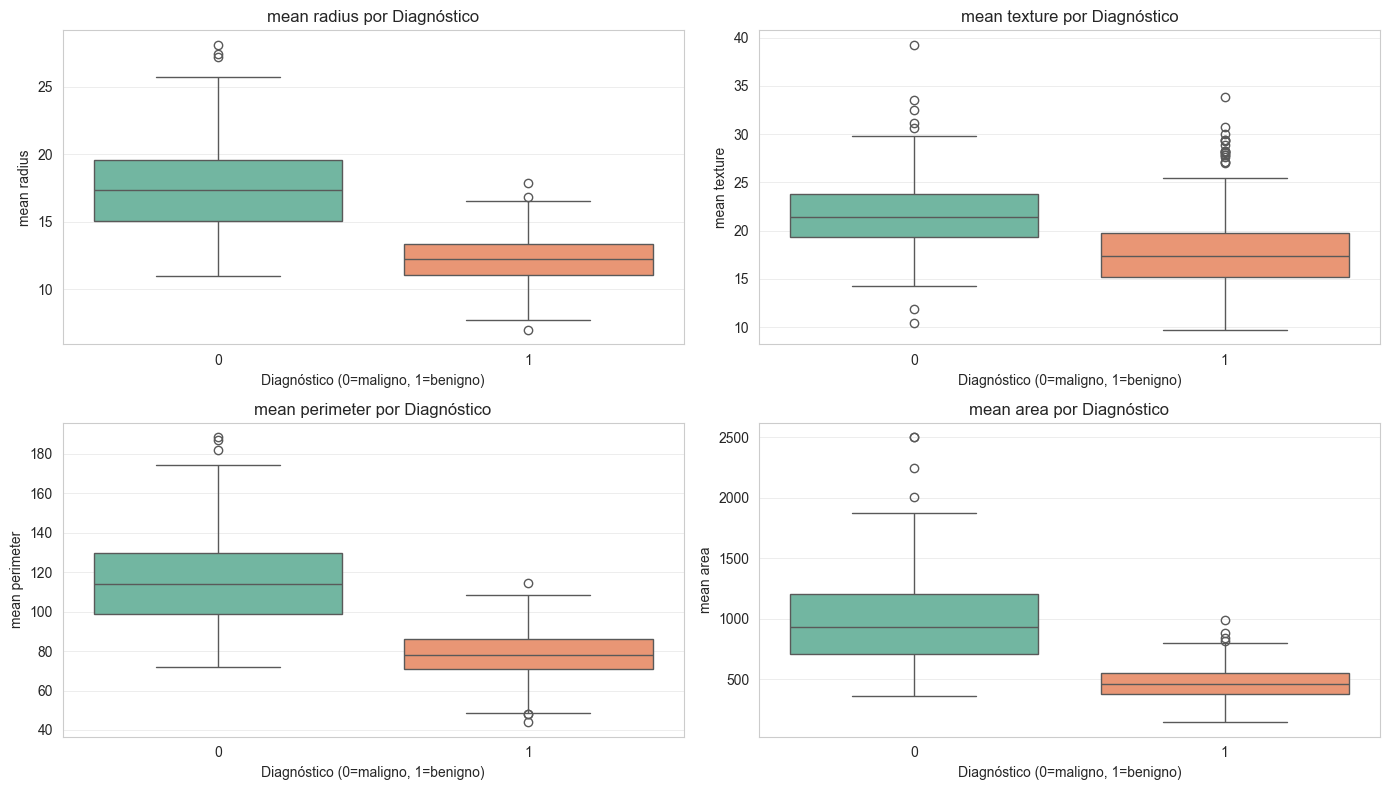

In [20]:
# Boxplots por diagnóstico
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, var in enumerate(vars_modelo):
    sns.boxplot(x='Diagnostico', y=var, data=df, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{var} por Diagnóstico')
    axes[i].set_xlabel('Diagnóstico (0=maligno, 1=benigno)')

plt.tight_layout()
plt.show()

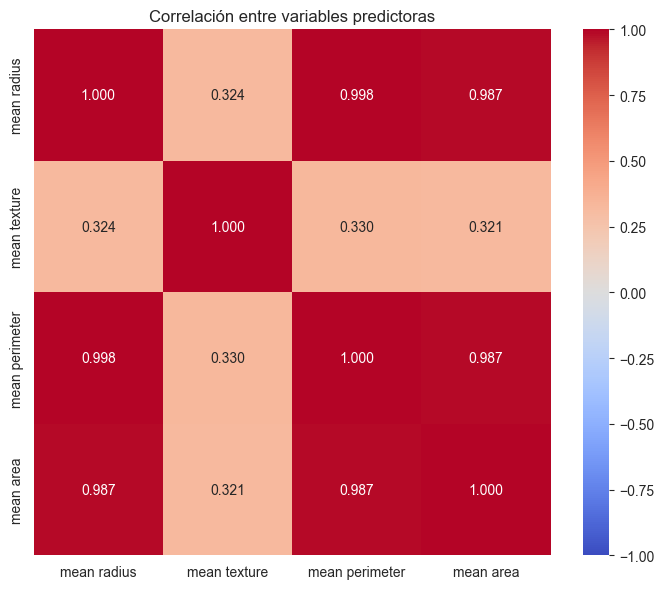

In [21]:
# Correlación entre variables
plt.figure(figsize=(7, 6))
sns.heatmap(df[vars_modelo].corr(), annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, fmt='.3f')
plt.title('Correlación entre variables predictoras')
plt.tight_layout()
plt.show()

In [22]:
# Ajustar regresión logística con statsmodels (da p-valores y OR)
X_sm = sm.add_constant(df[vars_modelo]) # agrega la columna de 1s para β₀
y_sm = df['Diagnostico']                # corre Newton-Raphson

modelo_logit = sm.Logit(y_sm, X_sm).fit(disp=False)
print(modelo_logit.summary())

                           Logit Regression Results                           
Dep. Variable:            Diagnostico   No. Observations:                  569
Model:                          Logit   Df Residuals:                      564
Method:                           MLE   Df Model:                            4
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.7187
Time:                        21:23:52   Log-Likelihood:                -105.68
converged:                       True   LL-Null:                       -375.72
Covariance Type:            nonrobust   LLR p-value:                1.437e-115
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -1.7729      6.870     -0.258      0.796     -15.238      11.692
mean radius        9.4287      1.640      5.751      0.000       6.215      12.642
mean texture      -0.2376      0.046

In [23]:
# Odds Ratios con intervalos de confianza al 95%
odds_ratios = pd.DataFrame({
    'Coeficiente': modelo_logit.params,
    'OR': np.exp(modelo_logit.params),
    'IC 2.5%': np.exp(modelo_logit.conf_int()[0]),
    'IC 97.5%': np.exp(modelo_logit.conf_int()[1]),
    'p-valor': modelo_logit.pvalues
}).round(4)

print("=== ODDS RATIOS ===\n")
print(odds_ratios)

=== ODDS RATIOS ===

                Coeficiente          OR   IC 2.5%     IC 97.5%  p-valor
const               -1.7729      0.1698    0.0000  119645.3293   0.7964
mean radius          9.4287  12440.8159  500.2941  309365.8457   0.0000
mean texture        -0.2376      0.7885    0.7205       0.8630   0.0000
mean perimeter      -1.1507      0.3164    0.2293       0.4367   0.0000
mean area           -0.0328      0.9678    0.9456       0.9905   0.0056


In [24]:
# Predicciones de probabilidad
y_pred_prob = modelo_logit.predict(X_sm)
y_pred = (y_pred_prob > 0.5).astype(int)

# Matriz de confusión
print("Matriz de confusión:\n")
print(confusion_matrix(y_sm, y_pred))

print("\nReporte de clasificación:\n")
print(classification_report(y_sm, y_pred, target_names=['maligno', 'benigno']))

print(f"Accuracy: {accuracy_score(y_sm, y_pred):.4f}")

Matriz de confusión:

[[183  29]
 [ 17 340]]

Reporte de clasificación:

              precision    recall  f1-score   support

     maligno       0.92      0.86      0.89       212
     benigno       0.92      0.95      0.94       357

    accuracy                           0.92       569
   macro avg       0.92      0.91      0.91       569
weighted avg       0.92      0.92      0.92       569

Accuracy: 0.9192


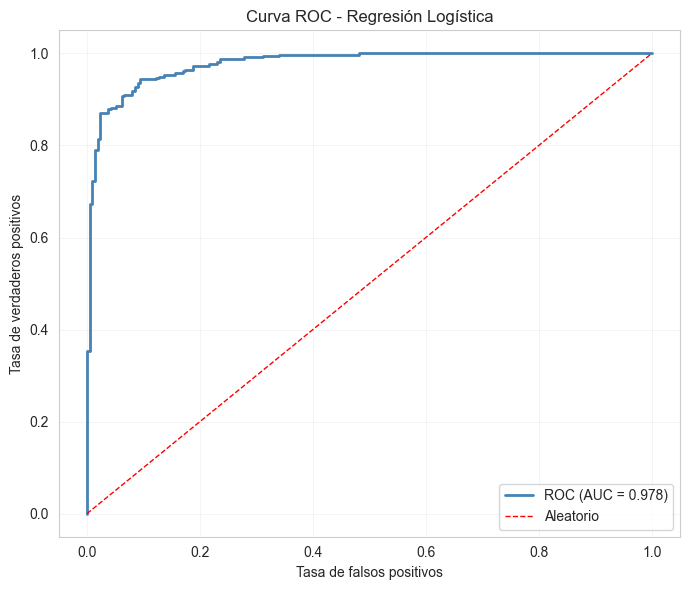

In [25]:
# Curva ROC
fpr, tpr, _ = roc_curve(y_sm, y_pred_prob)
auc = roc_auc_score(y_sm, y_pred_prob)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'ROC (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', lw=1, label='Aleatorio')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - Regresión Logística')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Implementación de la prueba de Hosmer-Lemeshow
def hosmer_lemeshow(y_true, y_prob, g=10):
    """
    Prueba de bondad de ajuste de Hosmer-Lemeshow.
    y_true: valores observados (0/1)
    y_prob: probabilidades predichas
    g: número de grupos (por defecto 10)
    """
    # Crear DataFrame auxiliar
    df_hl = pd.DataFrame({'y': y_true, 'p': y_prob})
    df_hl['grupo'] = pd.qcut(df_hl['p'], q=g, duplicates='drop')
    
    # Calcular observados y esperados por grupo
    hl_tabla = df_hl.groupby('grupo').agg(
        n=('y', 'size'),
        observados=('y', 'sum'),
        esperados=('p', 'sum'),
        p_medio=('p', 'mean')
    )
    hl_tabla['obs_no'] = hl_tabla['n'] - hl_tabla['observados']
    hl_tabla['esp_no'] = hl_tabla['n'] - hl_tabla['esperados']
    
    # Estadístico HL
    '''HL = (((hl_tabla['observados'] - hl_tabla['esperados'])**2 / hl_tabla['esperados']).sum()
          + ((hl_tabla['obs_no'] - hl_tabla['esp_no'])**2 / hl_tabla['esp_no']).sum())'''
    HL = ((hl_tabla['observados'] - hl_tabla['esperados']) ** 2 / (hl_tabla['observados'] * (1 - hl_tabla['p_medio']))).sum()
    
    gl = len(hl_tabla) - 2
    p_valor = 1 - stats.chi2.cdf(HL, gl)
    
    return HL, gl, p_valor, hl_tabla

HL, gl, p_valor, tabla = hosmer_lemeshow(y_sm, y_pred_prob, g=10)

print(f"Estadístico HL: {HL:.4f}")
print(f"Grados de libertad: {gl}")
print(f"p-valor: {p_valor:.4f}\n")

if p_valor > 0.05:
    print("✅ No se rechaza H0: el modelo tiene buen ajuste")
else:
    print("⚠️ Se rechaza H0: posible falta de ajuste")

print("\nTabla por grupos:")
print(tabla.round(3))

Estadístico HL: inf
Grados de libertad: 8
p-valor: 0.0000

⚠️ Se rechaza H0: posible falta de ajuste

Tabla por grupos:
                      n  observados  esperados  p_medio  obs_no  esp_no
grupo                                                                  
(-0.001, 3.74e-05]   57           0      0.000    0.000      57  57.000
(3.74e-05, 0.00606]  57           1      0.085    0.001      56  56.915
(0.00606, 0.25]      57           7      4.388    0.077      50  52.612
(0.25, 0.703]        57          24     28.073    0.493      33  28.927
(0.703, 0.904]       57          44     47.261    0.829      13   9.739
(0.904, 0.957]       56          54     52.441    0.936       2   3.559
(0.957, 0.979]       57          57     55.283    0.970       0   1.717
(0.979, 0.989]       57          56     56.132    0.985       1   0.868
(0.989, 0.994]       57          57     56.515    0.991       0   0.485
(0.994, 0.999]       57          57     56.821    0.997       0   0.179


In [27]:
# Pseudo R²
ll_modelo = modelo_logit.llf        # log-verosimilitud del modelo completo
ll_nulo = modelo_logit.llnull       # log-verosimilitud del modelo nulo - Solo intercepto
n = len(y_sm)

# McFadden
r2_mcfadden = 1 - (ll_modelo / ll_nulo)

# Cox-Snell
r2_coxsnell = 1 - np.exp((2 / n) * (ll_nulo - ll_modelo))

# Nagelkerke (ajusta Cox-Snell para que el máximo sea 1)
r2_nagelkerke = r2_coxsnell / (1 - np.exp((2 / n) * ll_nulo))

print("=== PSEUDO R² ===\n")
print(f"Log-verosimilitud modelo completo: {ll_modelo:.4f}")
print(f"Log-verosimilitud modelo nulo:     {ll_nulo:.4f}\n")
print(f"McFadden:    {r2_mcfadden:.4f}")
print(f"Cox-Snell:   {r2_coxsnell:.4f}")
print(f"Nagelkerke:  {r2_nagelkerke:.4f}")

=== PSEUDO R² ===

Log-verosimilitud modelo completo: -105.6834
Log-verosimilitud modelo nulo:     -375.7200

McFadden:    0.7187
Cox-Snell:   0.6129
Nagelkerke:  0.8362


In [28]:
# Comparación con sklearn
X_train, X_test, y_train, y_test = train_test_split(
    df[vars_modelo], df['Diagnostico'], test_size=0.3,
    random_state=42, stratify=df['Diagnostico']
)

# HL_w, gl_w, p_w, _ = hosmer_lemeshow(y_w_sm, y_prob_

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

modelo_sk = LogisticRegression(max_iter=1000)
modelo_sk.fit(X_train_sc, y_train)

y_pred_sk = modelo_sk.predict(X_test_sc)
y_prob_sk = modelo_sk.predict_proba(X_test_sc)[:, 1]

print("Accuracy en test: {:.4f}".format(accuracy_score(y_test, y_pred_sk)))
print("AUC en test:      {:.4f}".format(roc_auc_score(y_test, y_prob_sk)))
print("\nReporte de clasificación (test):\n")
print(classification_report(y_test, y_pred_sk, target_names=['maligno', 'benigno']))

Accuracy en test: 0.8889
AUC en test:      0.9647

Reporte de clasificación (test):

              precision    recall  f1-score   support

     maligno       0.87      0.83      0.85        64
     benigno       0.90      0.93      0.91       107

    accuracy                           0.89       171
   macro avg       0.88      0.88      0.88       171
weighted avg       0.89      0.89      0.89       171



## Actividad: Replicar todo el análisis con el dataset de Vinos - egresión Logística con el dataset de Vinos

El dataset de vinos tiene 3 clases. Para hacer regresión logística binaria, debemos convertir el problema a dos clases. Por ejemplo:
- Clase 0 (vino tinto A) vs. clases 1 y 2 (resto)
- O bien usar solo dos clases filtrando una

### Cargar el dataset con load_wine()

In [29]:
from sklearn.datasets import load_wine      # De sklearn importamos el dataset para trabajar 🤠

wine = load_wine()
X_w = pd.DataFrame(wine.data, columns=wine.feature_names)
y_w = pd.Series(wine.target, name='Clase')
df_w = pd.concat([X_w, y_w], axis=1)

print(f"Forma del dataset: {df_w.shape}")
print(f"Vinos por clase original: {dict(y_w.value_counts().sort_index())}")

Forma del dataset: (178, 14)
Vinos por clase original: {0: np.int64(59), 1: np.int64(71), 2: np.int64(48)}


### Convertir el problema a binario (por ejemplo, clase 0 vs. resto)

In [30]:
df_w['Clase_bin'] = (df_w['Clase'] == 0).astype(int)   # 1 = clase 0, 0 = resto

print(f"Clases binarias: {dict(df_w['Clase_bin'].value_counts())}")
print(f"Proporción de clase 0: {df_w['Clase_bin'].mean():.3f}")
df_w.head()

Clases binarias: {0: np.int64(119), 1: np.int64(59)}
Proporción de clase 0: 0.331


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase,Clase_bin
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,1
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,1
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,1
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,1
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,1


### Seleccionar 3 o 4 variables predictoras

In [31]:
vars_w = ['alcohol', 'malic_acid', 'ash', 'total_phenols']

### Explorar los datos: estadísticas, boxplots, correlación

In [32]:
print("Estadísticas descriptivas por clase (1 = clase 0, 0 = resto):\n")
print(df_w.groupby('Clase_bin')[vars_w].agg(['mean', 'std']).round(3))

Estadísticas descriptivas por clase (1 = clase 0, 0 = resto):

          alcohol        malic_acid           ash        total_phenols       
             mean    std       mean    std   mean    std          mean    std
Clase_bin                                                                    
0          12.632  0.685      2.498  1.249  2.322  0.286         2.025  0.556
1          13.745  0.462      2.011  0.689  2.456  0.227         2.840  0.339


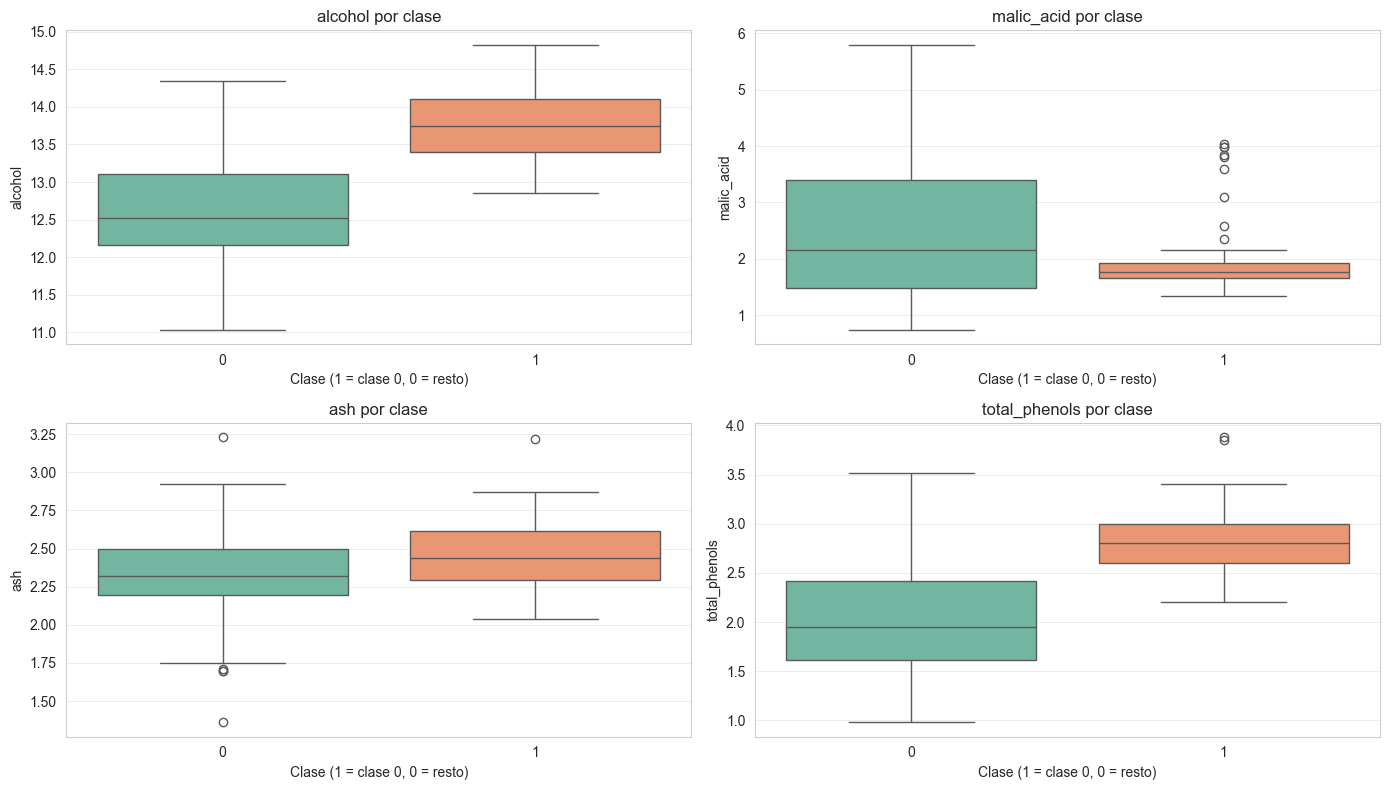

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for i, var in enumerate(vars_w):
    sns.boxplot(x='Clase_bin', y=var, data=df_w, ax=axes[i], palette='Set2')
    axes[i].set_title(f'{var} por clase')
    axes[i].set_xlabel('Clase (1 = clase 0, 0 = resto)')

plt.tight_layout()
plt.show()

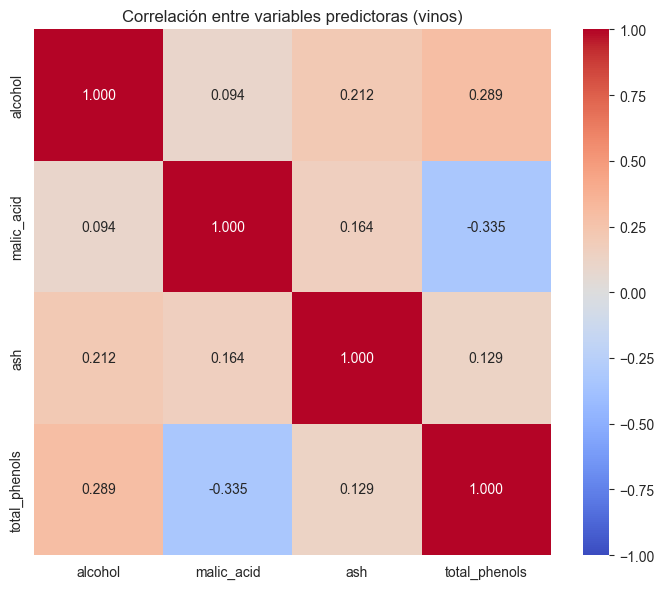

In [34]:
plt.figure(figsize=(7, 6))
sns.heatmap(df_w[vars_w].corr(), annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, fmt='.3f')
plt.title('Correlación entre variables predictoras (vinos)')
plt.tight_layout()
plt.show()

### Ajustar el modelo con statsmodels

In [35]:
X_w_sm = sm.add_constant(df_w[vars_w])   # columna de 1s para β₀
y_w_sm = df_w['Clase_bin']

modelo_w = sm.Logit(y_w_sm, X_w_sm).fit(disp=False)   # máxima verosimilitud (Newton-Raphson)
print(modelo_w.summary())

                           Logit Regression Results                           
Dep. Variable:              Clase_bin   No. Observations:                  178
Model:                          Logit   Df Residuals:                      173
Method:                           MLE   Df Model:                            4
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.6601
Time:                        21:23:53   Log-Likelihood:                -38.436
converged:                       True   LL-Null:                       -113.07
Covariance Type:            nonrobust   LLR p-value:                 2.929e-31
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -50.8074      8.817     -5.763      0.000     -68.087     -33.527
alcohol           3.0418      0.587      5.184      0.000       1.892       4.192
malic_acid       -0.2068      0.297     

### Interpretar los Odds Ratios

In [36]:
or_w = pd.DataFrame({
    'Coef': modelo_w.params,
    'OR': np.exp(modelo_w.params),
    'IC 2.5%': np.exp(modelo_w.conf_int()[0]),
    'IC 97.5%': np.exp(modelo_w.conf_int()[1]),
    'p': modelo_w.pvalues
}).round(4)

print("=== ODDS RATIOS (vinos) ===\n")
print(or_w)

=== ODDS RATIOS (vinos) ===

                  Coef       OR  IC 2.5%  IC 97.5%       p
const         -50.8074   0.0000   0.0000    0.0000  0.0000
alcohol         3.0418  20.9433   6.6317   66.1403  0.0000
malic_acid     -0.2068   0.8132   0.4539    1.4568  0.4869
ash             0.9753   2.6518   0.3494   20.1258  0.3456
total_phenols   3.3311  27.9680   6.6002  118.5133  0.0000


### Evaluar con matriz de confusión, ROC, Hosmer-Lemeshow y pseudo R²

In [37]:
# Probabilidades predichas y clasificación con umbral 0.5
y_prob_w = modelo_w.predict(X_w_sm)
y_pred_w = (y_prob_w > 0.5).astype(int)

print("Matriz de confusión:\n")
print(confusion_matrix(y_w_sm, y_pred_w))

print("\nReporte de clasificación:\n")
print(classification_report(y_w_sm, y_pred_w, target_names=['resto', 'clase 0']))

print(f"Accuracy: {accuracy_score(y_w_sm, y_pred_w):.4f}")

Matriz de confusión:

[[110   9]
 [  9  50]]

Reporte de clasificación:

              precision    recall  f1-score   support

       resto       0.92      0.92      0.92       119
     clase 0       0.85      0.85      0.85        59

    accuracy                           0.90       178
   macro avg       0.89      0.89      0.89       178
weighted avg       0.90      0.90      0.90       178

Accuracy: 0.8989


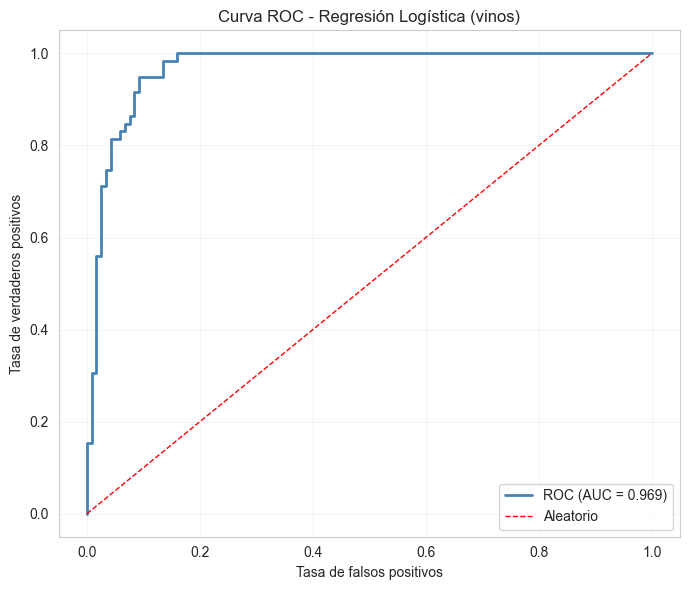

In [38]:
# Curva ROC
fpr_w, tpr_w, _ = roc_curve(y_w_sm, y_prob_w)
auc_w = roc_auc_score(y_w_sm, y_prob_w)

plt.figure(figsize=(7, 6))
plt.plot(fpr_w, tpr_w, color='steelblue', lw=2, label=f'ROC (AUC = {auc_w:.3f})')
plt.plot([0, 1], [0, 1], 'r--', lw=1, label='Aleatorio')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curva ROC - Regresión Logística (vinos)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Hosmer-Lemeshow
HL_w, gl_w, p_w, tabla_w = hosmer_lemeshow(y_w_sm, y_prob_w, g=10)

print(f"Estadístico HL: {HL_w:.4f}")
print(f"Grados de libertad: {gl_w}")
print(f"p-valor: {p_w:.4f}\n")

if p_w > 0.05:
    print("No se rechaza H0: el modelo tiene buen ajuste")
else:
    print("Se rechaza H0: posible falta de ajuste")

print("\nTabla por grupos:")
print(tabla_w.round(3))

Estadístico HL: inf
Grados de libertad: 8
p-valor: 0.0000

⚠Se rechaza H0: posible falta de ajuste

Tabla por grupos:
                       n  observados  esperados  p_medio  obs_no  esp_no
grupo                                                                   
(-0.000795, 0.00235]  18           0      0.018    0.001      18  17.982
(0.00235, 0.00503]    18           0      0.069    0.004      18  17.931
(0.00503, 0.0119]     18           0      0.154    0.009      18  17.846
(0.0119, 0.0233]      17           0      0.304    0.018      17  16.696
(0.0233, 0.0712]      18           0      0.774    0.043      18  17.226
(0.0712, 0.214]       18           3      2.414    0.134      15  15.586
(0.214, 0.608]        17           8      6.935    0.408       9  10.065
(0.608, 0.865]        18          15     13.542    0.752       3   4.458
(0.865, 0.971]        18          16     16.986    0.944       2   1.014
(0.971, 1.0]          18          17     17.806    0.989       1   0.194


In [40]:
# Pseudo R^2
ll_mod_w = modelo_w.llf      # log-verosimilitud del modelo completo
ll_nul_w = modelo_w.llnull   # log-verosimilitud del modelo nulo (solo intercepto)
n_w = len(y_w_sm)

r2_mcf_w = 1 - (ll_mod_w / ll_nul_w)
r2_cs_w = 1 - np.exp((2 / n_w) * (ll_nul_w - ll_mod_w))
r2_nag_w = r2_cs_w / (1 - np.exp((2 / n_w) * ll_nul_w))

print("=== PSEUDO R² (vinos) ===\n")
print(f"Log-verosimilitud modelo completo: {ll_mod_w:.4f}")
print(f"Log-verosimilitud modelo nulo:     {ll_nul_w:.4f}\n")
print(f"McFadden:    {r2_mcf_w:.4f}")
print(f"Cox-Snell:   {r2_cs_w:.4f}")
print(f"Nagelkerke:  {r2_nag_w:.4f}")

=== PSEUDO R² (vinos) ===

Log-verosimilitud modelo completo: -38.4358
Log-verosimilitud modelo nulo:     -113.0671

McFadden:    0.6601
Cox-Snell:   0.5677
Nagelkerke:  0.7892


### Comparar con sklearn

In [41]:
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    df_w[vars_w], df_w['Clase_bin'], test_size=0.3,
    random_state=42, stratify=df_w['Clase_bin']
)

scaler_w = StandardScaler()
X_train_w_sc = scaler_w.fit_transform(X_train_w)   # aprende media/desv. SOLO de train
X_test_w_sc = scaler_w.transform(X_test_w)         # aplica esas mismas a test

modelo_sk_w = LogisticRegression(max_iter=1000)
modelo_sk_w.fit(X_train_w_sc, y_train_w)

y_pred_sk_w = modelo_sk_w.predict(X_test_w_sc)
y_prob_sk_w = modelo_sk_w.predict_proba(X_test_w_sc)[:, 1]

print("Accuracy en test: {:.4f}".format(accuracy_score(y_test_w, y_pred_sk_w)))
print("AUC en test:      {:.4f}".format(roc_auc_score(y_test_w, y_prob_sk_w)))
print("\nMatriz de confusión (test):\n")
print(confusion_matrix(y_test_w, y_pred_sk_w))
print("\nReporte de clasificación (test):\n")
print(classification_report(y_test_w, y_pred_sk_w, target_names=['resto', 'clase 0']))

print("Coeficientes sklearn (variables estandarizadas):")
print(pd.Series(modelo_sk_w.coef_[0], index=vars_w).round(4))

Accuracy en test: 0.8333
AUC en test:      0.9259

Matriz de confusión (test):

[[32  4]
 [ 5 13]]

Reporte de clasificación (test):

              precision    recall  f1-score   support

       resto       0.86      0.89      0.88        36
     clase 0       0.76      0.72      0.74        18

    accuracy                           0.83        54
   macro avg       0.81      0.81      0.81        54
weighted avg       0.83      0.83      0.83        54

Coeficientes sklearn (variables estandarizadas):
alcohol          2.2517
malic_acid      -0.2398
ash              0.4824
total_phenols    1.8638
dtype: float64


### Conclusiones

1. Se transformó el problema de 3 clases a uno binario: **clase 0 vs. resto**
2. Con `alcohol`, `malic_acid`, `ash` y `total_phenols` el modelo logístico es significativo en conjunto (LLR p ≈ 3e-31). Las variables que realmente distinguen a la clase 0 son **alcohol** (OR ≈ 21) y **fenoles totales** (OR ≈ 28): a más alcohol y más fenoles, mayores los momios de que el vino sea de clase 0. `malic_acid` y `ash` no son significativas
3. El modelo **discrimina** muy bien (AUC = 0.969, accuracy = 0.899) y además está **bien calibrado** (Hosmer-Lemeshow p = 0.556). McFadden = 0.66 indica un ajuste excelente
4. En datos nuevos (sklearn, 30% de prueba) el desempeño baja un poco (accuracy = 0.833, AUC = 0.926), como se espera fuera de muestra
5. Comparado con el ejemplo de cáncer: aquí las predictoras no están correlacionadas entre sí, así que los Odds Ratios sí son interpretables y no hay cuasi-separación
6. Un modelo más simple, solo con `alcohol` y `total_phenols`, probablemente funcionaría casi igual de bien, ya que las otras dos variables no aportan información significativa

In [42]:
# Paso final :D!
# Celda extra para volver el notebook en un .html

!jupyter nbconvert --to html "Actividad7.ipynb"

[NbConvertApp] Converting notebook Actividad7.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 6 image(s).
[NbConvertApp] Writing 703950 bytes to Actividad7.html
